# Human lymph node: Fig. 4a-c

The saved joint embedding leads to the fixed spatial partition displayed in **Fig. 4a**. Follow the barcode alignment from embedding to tissue coordinates and final labels.

Read the stored outputs below in order. These cells load and plot archived results; they do not preprocess inputs, train models, cluster spots, or fit a new UMAP/t-SNE.

Data: `Published_Data_non_NASH/02_Human_lymph_node/`. The sharedoc download link will be added after the archive is uploaded.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
from IPython.display import display

repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Reproduce").is_dir())
sys.path.insert(0, str(repo / "Reproduce"))
from _shared.paper_plots import *
DATA_ROOT = Path(os.environ.get("MELON_PUBLISHED_DATA", repo / "Published_Data_non_NASH"))
DATA = DATA_ROOT / "02_Human_lymph_node"
assert DATA.is_dir(), "Place Published_Data_non_NASH beside Reproduce, or set MELON_PUBLISHED_DATA."


## 1. Load the saved representation and partition

`03_embeddings/MELON.csv` stores the joint representation. `04_clusters/final_clusters.csv` stores the final labels, tissue coordinates and reference annotations. Alignment uses barcode values, not CSV row position.

In [2]:
embedding = read_indexed(DATA / "03_embeddings/MELON.csv")
labels = read_indexed(DATA / "04_clusters/final_clusters.csv")
embedding = align_embedding(embedding, labels)
assert len(labels) == 3484
display(pd.DataFrame({"spots": [len(labels)], "embedding_dimensions": [embedding.shape[1]],
                       "MELON_domains": [labels.MELON.nunique()]}))

,spots,embedding_dimensions,MELON_domains
0,3484,128,10


## 2. Place the fixed labels on the tissue — Fig. 4a

Each dot is one saved spot. The RNA-only, Protein-only and MELON columns are existing partitions. The notebook uses categorical colors for inspection; the manuscript montage below retains its original display-color matching.

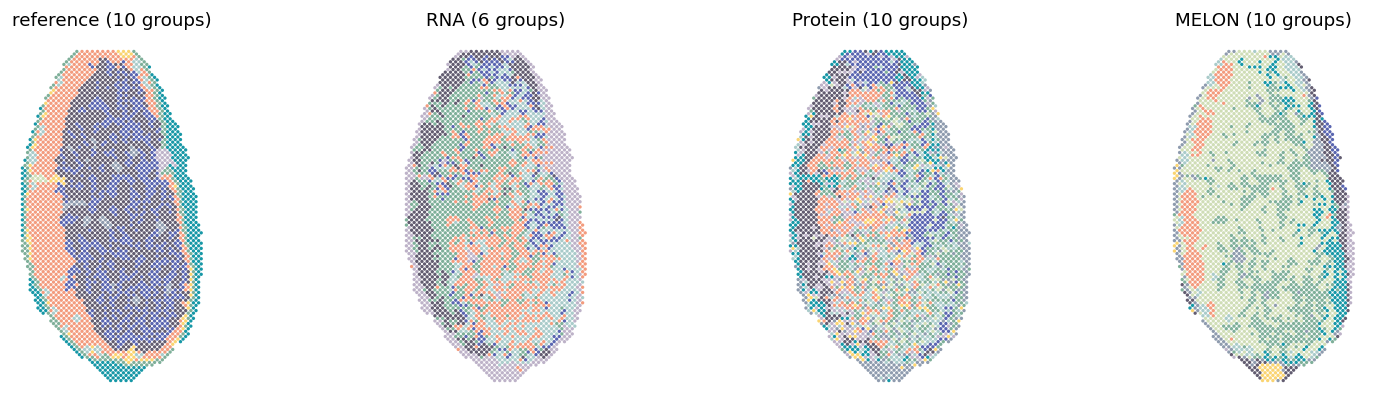

In [3]:
show(spatial_panels(labels, ["reference", "RNA", "Protein", "MELON"], ncols=4))

## 3. Read the method-comparison columns

The comparison panels use the same coordinates and barcode cohort. SCIGMA is read from the saved final column, not reclustered from its embedding. The archive also retains a `totalvi` column; it is not included in the seven-method main comparison.

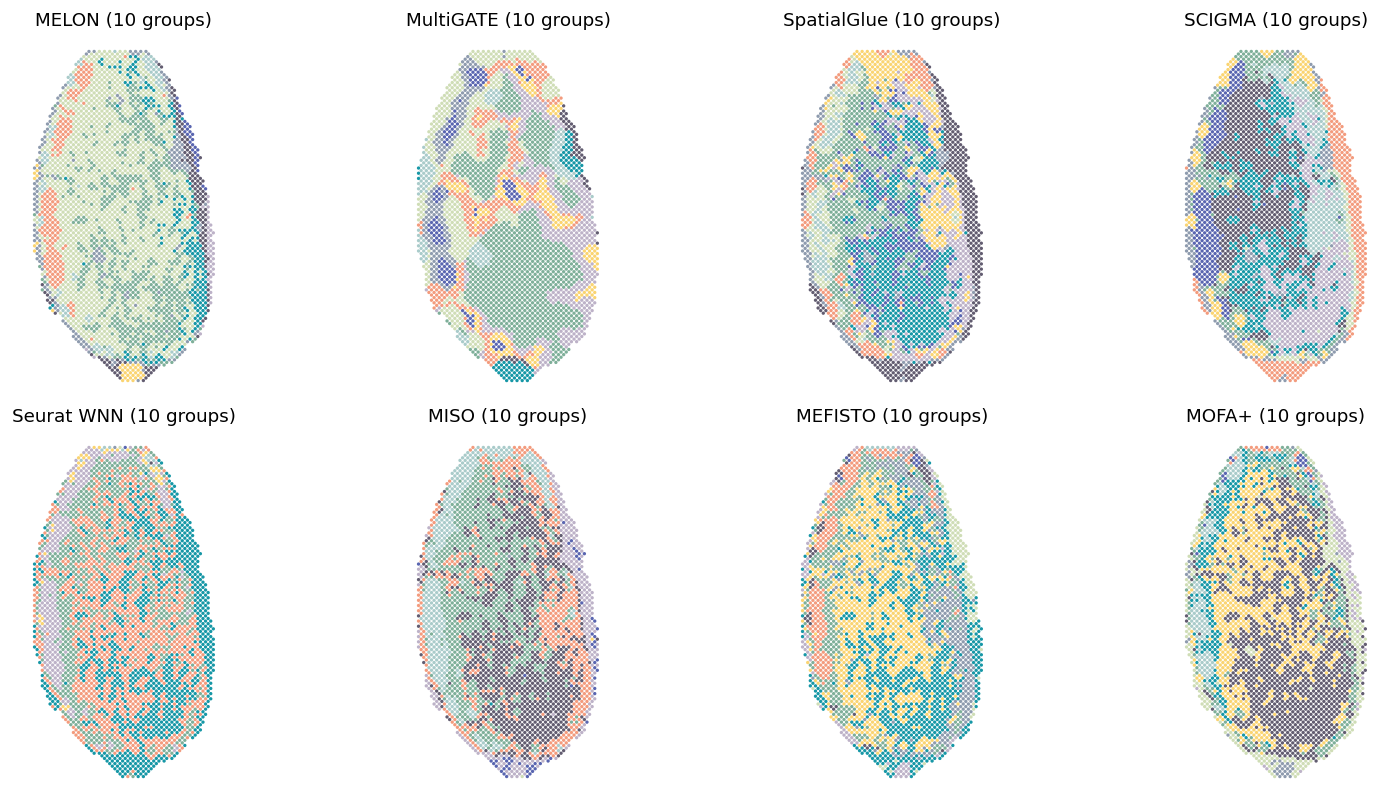

In [4]:
show(spatial_panels(labels, ["MELON", "MultiGATE", "SpatialGlue", "SCIGMA",
                            "Seurat WNN", "MISO", "MEFISTO", "MOFA+"], ncols=4))

## 4. Read the stored t-SNE — Supplementary Fig. 7e

The supplementary t-SNE has its own saved source embedding and domain column. Read both from `03_embeddings/supplementary_tsne/`; do not substitute the main-comparison embedding or fit t-SNE again.

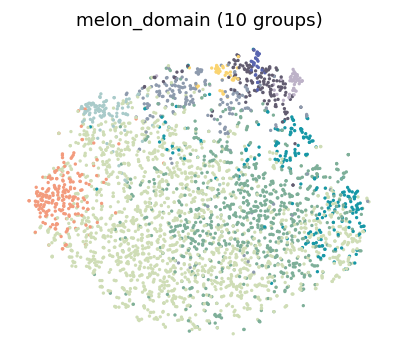

In [5]:
tsne = read_indexed(DATA / "03_embeddings/supplementary_tsne/saved_tsne.csv")
tsne_source = read_indexed(DATA / "03_embeddings/supplementary_tsne/source_embedding.csv")
tsne_source = align_embedding(tsne_source, tsne)
show(spatial_panels(tsne, ["melon_domain"], x="TSNE1", y="TSNE2", ncols=1, invert_y=False))

## Corresponding manuscript figure

The left half is the lymph-node analysis: **a**, spatial partitions; **b**, benchmark scores; **c**, RNA-protein abundance and decoder pair activity.

![Manuscript Figure 4](../figures/paper_figure_4.png)

*Original manuscript figure, supplied PDF dated 2026-11-03. The notebook plots above are views of the saved data, not a replacement for this assembled figure.*

## Panel sources

| Panel | Source in this archive |
| --- | --- |
| 4a | `04_clusters/final_clusters.csv`, `01_source_data/tissue_reference.png` |
| 4b | Main labels and references are present; the final multi-resolution benchmark summary is separate |
| 4c | RNA and ADT source matrices are present; the saved decoder pair-activity table is separate |
| Supplementary 7e | `03_embeddings/supplementary_tsne/saved_tsne.csv` and `source_embedding.csv` |

The modeling matrices and final labels belong to different stages. The missing paired-activity values are not inferred from cluster labels.